<a href="https://colab.research.google.com/github/Mohamed-ktari/Advanced-machine-learning-/blob/main/TP_4_Reinforcement_Learning_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Libraries**



In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

**MDP class**

In [2]:
# MDP class
# The class takes four parameters: transition_probs, rewards, initial_state, and terminal_states.

# transition_probs: dictionary that defines the probabilities of transitioning from one state to another given a certain action.
# rewards: dictionary that specifies the rewards received when transitioning from one state to another using a particular action.
# initial_state: starting state of the MDP.
# terminal_states: list of states that are considered terminal, meaning the process ends when these states are reached.

class MDP:
    def __init__(self, transition_probs, rewards, initial_state, terminal_states=None):
        self.transition_probs = transition_probs
        self.rewards = rewards
        self.initial_state = initial_state
        self.state = initial_state
        self.terminal_states = terminal_states if terminal_states else []

    def get_all_states(self):
        return list(self.transition_probs.keys())

    def get_possible_actions(self, state):
        return list(self.transition_probs[state].keys())

    def get_next_states(self, state, action):
        return self.transition_probs[state][action]

    def get_transition_prob(self, state, action, next_state):
        return self.transition_probs[state][action].get(next_state, 0) # Returns 0 if next_state is not found.

    def get_reward(self, state, action, next_state):
        return self.rewards.get(state, {}).get(action, {}).get(next_state, 0)

    def reset(self):
        self.state = self.initial_state
        return self.state

    def is_terminal(self, state):
        return state in self.terminal_states

    def get_next_state(self, state, action):
        next_states = self.transition_probs[state][action]
        next_state = max(next_states, key=next_states.get)
        return next_state

    def step(self, action):
        next_states_probs = self.transition_probs[self.state][action]
        next_states = list(next_states_probs.keys())
        probabilities = list(next_states_probs.values())
        next_state = np.random.choice(next_states, p=probabilities)
        reward = self.get_reward(self.state, action, next_state)
        self.state = next_state
        done = self.is_terminal(next_state)
        return next_state, reward, done

**Define the transition probabilities and rewards**

In [5]:
transition_probs = {
    's0': {
        'a0': {'s0': 0.6, 's1': 0.4},
        'a1': {'s1': 0.8, 's2': 0.2}
    },
    's1': {
        'a0': {'s0': 0.3, 's2': 0.7},
        'a1': {'s2': 1.0}
    },
    's2': {
        'a0': {'s1': 0.5, 's2': 0.5},
        'a1': {'s0': 0.3, 's2': 0.7}
    }
}

rewards = {
    's0': {
        'a0': {'s0': 0, 's1': 0},
        'a1': {'s1': 2, 's2': 0}
    },
    's1': {
        'a0': {'s0': 0, 's2': 3},
        'a1': {'s2': 0}
    },
    's2': {
        'a0': {'s1': 0, 's2': 0},
        'a1': {'s0': -2, 's2': 0}
    }
}

# YOUR CODE HERE
states=list(transition_probs.keys())
# YOUR CODE HERE
actions=list(transition_probs[states[0]].keys())
print(states)
print(actions)

['s0', 's1', 's2']
['a0', 'a1']


**Getting familiar with MDP class**

In [6]:
initial_state = 's0'
terminal_states = ['s2']

In [7]:

# Create the MDP instance
mdp = MDP(transition_probs, rewards, initial_state, terminal_states)

# Get all states
all_states = mdp.get_all_states()
print(f"All states: {all_states}")

# Get possible actions from state 's0'
possible_actions = mdp.get_possible_actions('s0')
print(f"Possible actions from 's0': {possible_actions}")

# Get next states for action 'a0' from state 's0'
next_states = mdp.get_next_states('s0', 'a0')
print(f"Next states for action 'a0' from state 's0': {next_states}")

# Get transition probability from 's0' to 's1' with action 'a0'
transition_prob = mdp.get_transition_prob('s0', 'a0', 's1')
print(f"Transition probability from 's0' to 's1' with action 'a0': {transition_prob}")

# Get the reward of transitioning from state to next state by taking action
reward = mdp.get_reward('s0', 'a0', 's1')
print(f"Reward from 's0' to 's1' with action 'a0': {reward}")

state,reward, done = mdp.step('a0')
print(f"Current state: {mdp.state}")

All states: ['s0', 's1', 's2']
Possible actions from 's0': ['a0', 'a1']
Next states for action 'a0' from state 's0': {'s0': 0.6, 's1': 0.4}
Transition probability from 's0' to 's1' with action 'a0': 0.4
Reward from 's0' to 's1' with action 'a0': 0
Current state: s0


# **Solving the MDP with Value Iteration algorithm**

In [12]:
def initialize_value_function(states):
    """
    Inputs:
      states: list of all states in the MDP.

    Returns:
      dict: dictionary with states as keys and 0 as initial values.
    """
    # YOUR CODE HERE
    return dict.fromkeys(states, 0)

print(initialize_value_function(states))

{'s0': 0, 's1': 0, 's2': 0}


In [18]:
def update_value_function(mdp, value_function, discount_factor):
    """
    Inputs:
      mdp: your mdp instance.
      value_function: current value function.
      discount_factor: discount factor for future rewards.

    Returns:
      dict: updated value function.
    """
    new_value_function = value_function.copy()

    for state in mdp.get_all_states():
        if not mdp.is_terminal(state):
            max_value = float('-inf')
            for action in mdp.get_possible_actions(state):
                # initialize the expected value: YOUR CODE HERE
                expected_value = 0
                for next_state in mdp.get_next_states(state, action):
                    transition_prob = mdp.get_transition_prob(state, action, next_state)
                    reward = mdp.get_reward(state, action, next_state)
                    expected_value +=  transition_prob * (reward + discount_factor * value_function[next_state])
                max_value = max(expected_value, max_value)
            new_value_function[state] = max_value

    return new_value_function

print(update_value_function(mdp, initialize_value_function(states), 0.9))

{'s0': 1.6, 's1': 2.0999999999999996, 's2': 0}


In [24]:
def value_iteration(mdp, discount_factor, threshold):
    """
    Inputs:
      mdp: your mdp instance.
      discount_factor: discount factor for future rewards.
      threshold: threshold for convergence.

    Returns:
      dict: optimal value function.
      list: history of value functions over iterations.
    """
    # initialize the value function: YOUR CODE HERE
    value_function = initialize_value_function(mdp.get_all_states())
    history = [value_function.copy()]
    # iterate until convergence
    # YOUR CODE HERE
    while True:
        new_value_function = update_value_function(mdp, value_function, discount_factor)
        history.append(new_value_function.copy())
        delta = max(abs(new_value_function[s] - value_function[s]) for s in value_function)
        value_function = new_value_function
        if delta < threshold:
            break
    return value_function, history
mdp = MDP(transition_probs, rewards, initial_state='s0')
print(value_iteration(mdp, 0.9, 0.01)[0])

{'s0': 10.281619495901786, 's1': 10.023831390432097, 's2': 8.185184959547493}


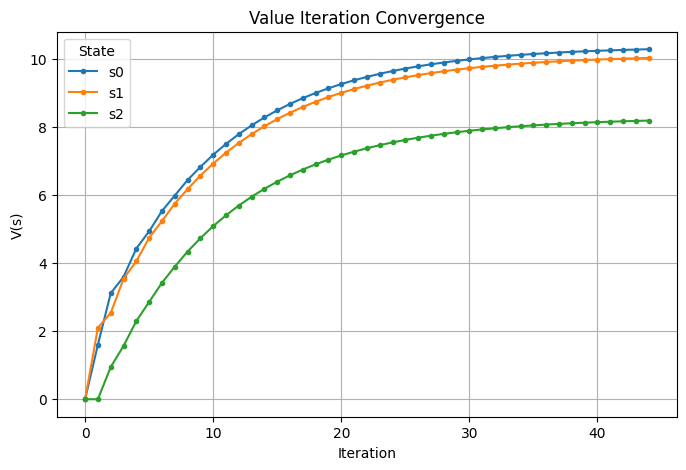

{'s0': 10.281619495901786, 's1': 10.023831390432097, 's2': 8.185184959547493}
Converged in 44 iterations


In [26]:
# plot convergence

discount_factor = 0.9
threshold = 1e-2

optimal_values, history = value_iteration(mdp, discount_factor, threshold)

plt.figure(figsize=(8, 5))
for state in history[0]:
    plt.plot([v[state] for v in history], marker="o", markersize=3, label=state)

plt.xlabel("Iteration")
plt.ylabel("V(s)")
plt.title("Value Iteration Convergence")
plt.legend(title="State")
plt.grid(True)
plt.show()

print(optimal_values)
print(f"Converged in {len(history) - 1} iterations")

**Question 1**\
**Purpose of the discount factor γ:** it controls how much the agent values future rewards compared to immediate ones. In the Bellman update, a reward received `k` steps later is weighted by `γ^k`. A small γ makes the agent short-sighted (it favors immediate rewards), while a γ close to 1 makes it far-sighted. It also guarantees that the sum of rewards stays finite and that value iteration converges.

**Possible values:** γ ∈ [0, 1]. With γ = 0 only the immediate reward counts; with γ < 1 convergence is guaranteed; with γ = 1 the future is not discounted, which only works if the process reaches a terminal state, otherwise the values may diverge.

**Question 2:**\
**Stopping criterion:** Value iteration stops when the largest change of the value function between two successive iterations, falls below a small threshold `θ`. Since the values converge only asymptotically, we can never reach the exact fixed point in finite time, so this criterion tells us when the values are close enough to `V*`.\
 A terminal state does not remove the need for it: the values of the non-terminal states still evolve over the iterations and are only approximately correct after a finite number of updates. The criterion would only be unnecessary in the special case of an acyclic MDP where every path reaches a terminal state after a bounded number of steps, since then the values become exact after that many iterations. In general (and in an MDP with cycles), it is still needed.


**Question 3:**\
**Optimal policy:** A policy `π` maps each state to an action . An optimal policy `π*` is a policy that maximizes the expected discounted cumulative reward from every state, i.e. `V^{π*}(s) ≥ V^π(s)` for all states `s` and all policies `π`. It is obtained from the optimal value function by acting greedily: `π*(s) = argmax_a Σ_{s'} P(s'|s,a) [R(s,a,s') + γ·V*(s')]`.

In [28]:
def get_optimal_policy(mdp, value_function, discount_factor):
    """
    Inputs:
      mdp: your MDP instance.
      value_function: the converged value function.
      discount_factor: discount factor for future rewards.

    Returns:
      dict: optimal policy.
    """
    policy = {}

    for state in mdp.get_all_states():
        if mdp.is_terminal(state):
            policy[state] = None
            continue

        best_action = None
        best_value = float('-inf')

        for action in mdp.get_possible_actions(state):
            expected_value = 0
            for next_state in mdp.get_next_states(state, action):
                transition_prob = mdp.get_transition_prob(state, action, next_state)
                reward = mdp.get_reward(state, action, next_state)
                expected_value += transition_prob * (reward + discount_factor * value_function[next_state])

            if expected_value > best_value:
                best_value = expected_value
                best_action = action

        policy[state] = best_action

    return policy

In [29]:
print(get_optimal_policy(mdp, optimal_values, 0.9))

{'s0': 'a1', 's1': 'a0', 's2': 'a0'}


**Question 4 & Question 5: Optimal policy**

The optimal policy extracted from the converged value function is:

| State | Optimal action |
|-------|----------------|
| s0    | a1             |
| s1    | a0             |
| s2    | a0             |

- **s0 → a1:** it moves to `s1` with probability 0.8 and earns a reward of 2 on that transition, which is the best immediate gain from `s0`.
- **s1 → a0:** it reaches `s2` with probability 0.7 and earns a reward of 3, the largest reward in the MDP.
- **s2 → a0:** it avoids `a1`, which carries a penalty of −2 when returning to `s0`, and keeps a good chance of moving back to `s1`, where the high-reward action is available.

In short, the policy steers the agent toward `s1`, from where it can collect the reward of 3.

# **Solving the MDP with Q-learning**

**Question 6**

**Question 7**

In [30]:
def initialize_q_table(states, actions):
    """
    Inputs:
      states: all possible states
      actions: all possible actions.

    Returns:
      dict: Q-table initialized.
    """
    q_table = {}
    for state in states:
        q_table[state] = {action: 0 for action in actions}
    return q_table

In [31]:
print(initialize_q_table(states, actions))

{'s0': {'a0': 0, 'a1': 0}, 's1': {'a0': 0, 'a1': 0}, 's2': {'a0': 0, 'a1': 0}}


**Question 8**

In [32]:
def choose_action(state, Q, epsilon):
    """
    Inputs:
      state: current state of the agent.
      Q: Q-table.
      epsilon: exploration rate.

    Returns:
      action: chosen action.
    """
    if random.random() < epsilon:
        return random.choice(list(Q[state].keys()))

    return max(Q[state], key=Q[state].get)


In [33]:
def get_next_state_and_reward(state, action):
    """
    Inputs:
      state: the current state of the agent.
      action: the action taken by the agent.

    Returns:
      next_state: the next state of the agent.
      reward: the reward received for transitioning to the next state.
    """

    next_states_probs = mdp.transition_probs[state][action]
    next_states = list(next_states_probs.keys())
    probabilities = list(next_states_probs.values())

    next_state = np.random.choice(next_states, p=probabilities)

    reward = mdp.get_reward(state, action, next_state)

    return next_state, reward

In [ ]:
def q_learning(states, actions, episodes, max_steps_per_episode, alpha, epsilon, gamma):
    """
    Inputs:
      states: all possible states.
      actions: all possible actions.
      episodes: number of episodes to run.
      max_steps_per_episode: maximum steps per episode.
      alpha: learning rate.
      epsilon: exploration rate.
      gamma: discount factor.

    Returns:
      Q: The learned Q-table.
      policy: The optimal policy derived from the Q-table.
    """
    Q = initialize_q_table(states, actions)

    for episode in range(episodes):
        # start each episode from the initial state
        state = mdp.reset()

        for step in range(max_steps_per_episode):
            # choose an action (epsilon-greedy)
            action = choose_action(state, Q, epsilon)

            # interact with the environment
            next_state, reward = get_next_state_and_reward(state, action)

            # Q-learning update
            best_next_value = max(Q[next_state].values())
            Q[state][action] += alpha * (reward + gamma * best_next_value - Q[state][action])

            # move to the next state
            state = next_state

            # stop the episode if a terminal state is reached
            if mdp.is_terminal(state):
                break

    # derive the greedy policy from the learned Q-table
    policy = {s: max(Q[s], key=Q[s].get) for s in states}

    return Q, policy

**Question 9**

**Question 10**

In [ ]:
# Plot the average rewards

**Question 11**

**Question 12**